# LAB1 – Bài 2 (Trang 28): Khảo sát và tiền xử lý dữ liệu Bank marketing
**Sinh viên:** Đinh Văn Bình – **MSSV:** 6351071007

## Câu 5: Thống kê số lần liên hệ khách hàng và khảo sát sự liên quan với thuộc tính quyết định (y)

*Ghi chú:* tương ứng với Câu 5 của phần hướng dẫn. Titanic cộng `sibsp + parch` thành số người đi cùng (`relatives`) và tạo cờ `not_alone`. Với Bank marketing, hai thuộc tính đếm tương tự là:
- `campaign`: số lần liên hệ khách trong chiến dịch hiện tại (tính cả lần cuối),
- `previous`: số lần đã liên hệ khách trong các chiến dịch trước.

Ta tạo thuộc tính **`total_contacts = campaign + previous`** (tổng số lần liên hệ) và cờ **`contacted_before`** (1 nếu khách đã từng được liên hệ ở chiến dịch trước).

In [1]:
print('Họ tên: Đinh Văn Bình - MSSV: 6351071007')

Họ tên: Đinh Văn Bình - MSSV: 6351071007


### Bước 1. Import thư viện và đọc dữ liệu

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
%matplotlib inline
from matplotlib import pyplot as plt

with open('bank-additional-full.csv') as f:
    df = pd.read_csv(f, sep=';')

df['subscribed'] = (df['y'] == 'yes').astype(int)
print('Kích thước dữ liệu (dòng, cột):', df.shape)

Kích thước dữ liệu (dòng, cột): (41188, 22)


### Bước 2. Tạo thuộc tính tổng số lần liên hệ và cờ đã từng được liên hệ

In [3]:
df['total_contacts'] = df['campaign'] + df['previous']
df['contacted_before'] = (df['previous'] > 0).astype(int)

print(df[['campaign', 'previous', 'total_contacts']].describe().round(2))
print('\nSố khách theo contacted_before (0 = chưa từng, 1 = đã từng được liên hệ):')
print(df['contacted_before'].value_counts())

       campaign  previous  total_contacts
count  41188.00  41188.00        41188.00
mean       2.57      0.17            2.74
std        2.77      0.49            2.78
min        1.00      0.00            1.00
25%        1.00      0.00            1.00
50%        2.00      0.00            2.00
75%        3.00      0.00            3.00
max       56.00      7.00           56.00

Số khách theo contacted_before (0 = chưa từng, 1 = đã từng được liên hệ):
contacted_before
0    35563
1     5625
Name: count, dtype: int64


### Bước 3. Thống kê tỷ lệ đăng ký theo số lần liên hệ

In [4]:
def rate_table(col):
    t = df.groupby(col)['subscribed'].agg(['size', 'mean'])
    t.columns = ['số khách', 'tỷ lệ đăng ký (%)']
    t['tỷ lệ đăng ký (%)'] = (t['tỷ lệ đăng ký (%)'] * 100).round(1)
    return t

print('Theo contacted_before:'); print(rate_table('contacted_before'), end='\n\n')
print('Theo previous:'); print(rate_table('previous'), end='\n\n')
print('Theo campaign (1–15 lần):'); print(rate_table('campaign').loc[1:15], end='\n\n')
print('Theo total_contacts (1–15 lần):'); print(rate_table('total_contacts').loc[1:15])
print('\nSố khách có total_contacts > 15:', (df['total_contacts'] > 15).sum())

Theo contacted_before:
                  số khách  tỷ lệ đăng ký (%)
contacted_before                             
0                    35563                8.8
1                     5625               26.6

Theo previous:
          số khách  tỷ lệ đăng ký (%)
previous                             
0            35563                8.8
1             4561               21.2
2              754               46.4
3              216               59.3
4               70               54.3
5               18               72.2
6                5               60.0
7                1                0.0

Theo campaign (1–15 lần):
          số khách  tỷ lệ đăng ký (%)
campaign                             
1            17642               13.0
2            10570               11.5
3             5341               10.7
4             2651                9.4
5             1599                7.5
6              979                7.7
7              629                6.0
8              400          

### Bước 4. Vẽ biểu đồ tỷ lệ đăng ký theo tổng số lần liên hệ
Chỉ vẽ `total_contacts` ≤ 15 vì số khách lớn hơn 15 lần rất ít (phân bố lệch phải, tối đa 56 lần).

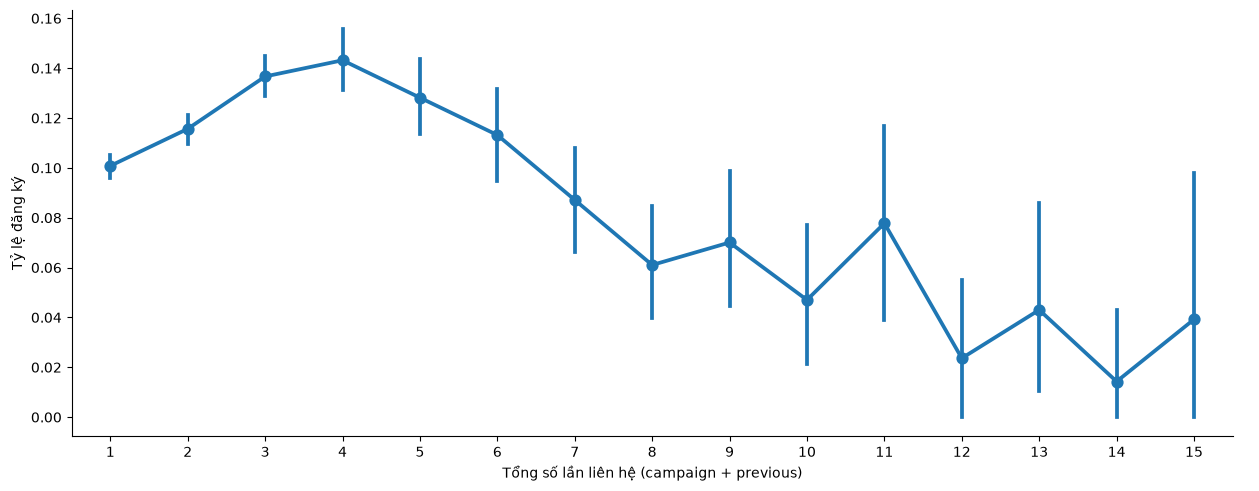

In [5]:
axes = sns.catplot(x='total_contacts', y='subscribed', data=df[df['total_contacts'] <= 15],
                   aspect=2.5, kind='point')
_ = axes.set_axis_labels('Tổng số lần liên hệ (campaign + previous)', 'Tỷ lệ đăng ký')

### Bước 5. Vẽ riêng từng thành phần: `campaign` và `previous`

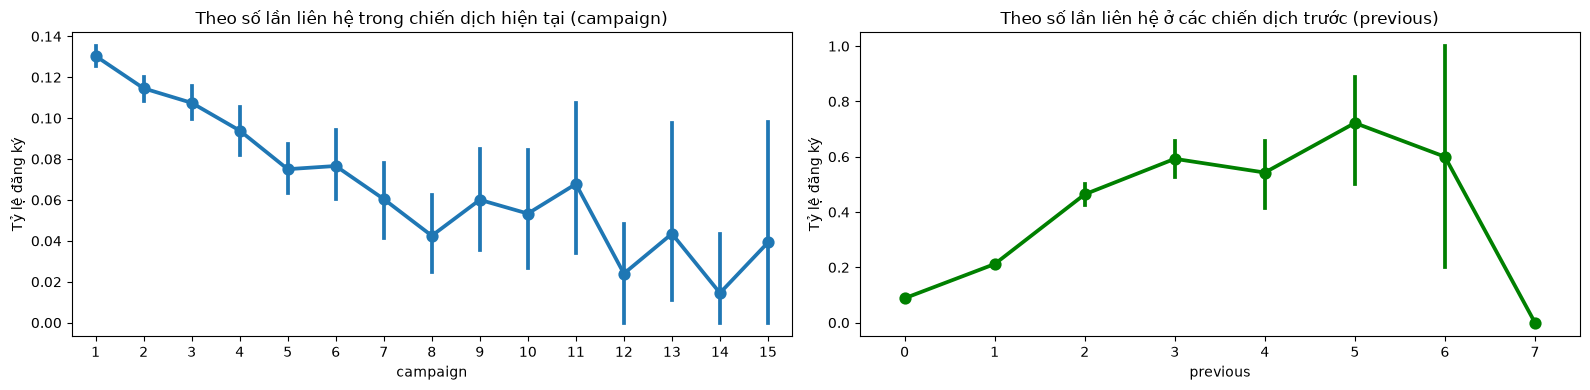

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
sns.pointplot(x='campaign', y='subscribed', data=df[df['campaign'] <= 15], ax=axes[0])
axes[0].set_title('Theo số lần liên hệ trong chiến dịch hiện tại (campaign)')
axes[0].set_ylabel('Tỷ lệ đăng ký')
sns.pointplot(x='previous', y='subscribed', data=df, ax=axes[1], color='g')
axes[1].set_title('Theo số lần liên hệ ở các chiến dịch trước (previous)')
axes[1].set_ylabel('Tỷ lệ đăng ký')
plt.tight_layout()

### Nhận xét
- **Phân bố:** đa số khách chỉ được gọi **1–3 lần** trong chiến dịch hiện tại (trung vị `campaign` = 2), nhưng có vài khách bị gọi rất nhiều lần (tối đa 56), nên phân bố lệch phải. **86%** khách (35 563 người) chưa từng được liên hệ ở chiến dịch trước (`previous = 0`).
- **`contacted_before` ảnh hưởng rất mạnh:** khách đã từng được liên hệ ở chiến dịch trước có tỷ lệ đăng ký **~26.6%**, gấp 3 lần khách mới (**~8.8%**). Tương tự `not_alone` ở Titanic, đây là cờ nhị phân rất có ích cho mô hình.
- **`previous` càng lớn, tỷ lệ đăng ký càng tăng:** 0 lần ~8.8% → 1 lần ~21% → 2 lần ~46% → 3 lần ~59%. Các giá trị từ 5 lần trở lên có rất ít khách nên biểu đồ dao động mạnh, khoảng tin cậy rộng.
- **`campaign` thì ngược lại:** gọi càng nhiều lần trong cùng chiến dịch, tỷ lệ đăng ký càng **giảm** (13% ở lần 1 → chỉ khoảng 2–7% từ lần 8 trở đi). Khách đồng ý thường đồng ý ngay từ vài cuộc gọi đầu; gọi nhiều lần không hiệu quả.
- **`total_contacts`:** tỷ lệ tăng nhẹ từ 1 đến khoảng **3–4 lần (~14%)**, sau đó giảm dần (dưới 9% từ 7 lần trở lên). Giống `relatives` ở Titanic: có một khoảng giá trị “vừa phải” cho kết quả tốt nhất.
- **Kết luận:** nên giữ riêng `previous`/`contacted_before` (ảnh hưởng tích cực) và `campaign` (ảnh hưởng tiêu cực). Cộng gộp thành `total_contacts` làm hai xu hướng trái ngược triệt tiêu nhau một phần.